# All Models & Model Comparison

**Project:** Predicting Performance Trajectories of Women Micro-Enterprises: An Early Warning Framework

This notebook trains and compares all three planned classification models using the same modelling dataset and evaluation framework:

1. Logistic Regression: baseline model
2. Random Forest
3. XGBoost

### Evaluation strategy

Because the dataset is relatively small and the outcome may be imbalanced, this notebook uses **nested stratified cross-validation**.

The outer folds estimate generalisation performance.  
The inner folds tune model hyperparameters.

Primary evaluation metrics:

- Macro-F1
- Balanced Accuracy
- Accuracy
- Macro Precision
- Macro Recall
- Macro ROC-AUC (OvR)

The confusion matrix is created from pooled out-of-fold predictions.


In [1]:
# 0. Setup

from google.colab import drive
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/24088950_MAI_Research"
)

OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

PRIMARY_PATH = (
    OUTPUT_DIR
    / "final_modelling_dataset_primary.csv"
)

SENSITIVITY_PATH = (
    OUTPUT_DIR
    / "final_modelling_dataset_sensitivity.csv"
)

RESULTS_DIR = OUTPUT_DIR / "model_results"
RESULTS_DIR.mkdir(exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Primary dataset:", PRIMARY_PATH)
print("Sensitivity dataset:", SENSITIVITY_PATH)
print("Results folder:", RESULTS_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/24088950_MAI_Research
Primary dataset: /content/drive/MyDrive/24088950_MAI_Research/outputs/final_modelling_dataset_primary.csv
Sensitivity dataset: /content/drive/MyDrive/24088950_MAI_Research/outputs/final_modelling_dataset_sensitivity.csv
Results folder: /content/drive/MyDrive/24088950_MAI_Research/outputs/model_results


## 1. Install and Import XGBoost


In [2]:
# 1. Install XGBoost if required

try:
    from xgboost import XGBClassifier
    print("XGBoost is already available.")
except ImportError:
    !pip -q install xgboost
    from xgboost import XGBClassifier
    print("XGBoost installed successfully.")

XGBoost is already available.


## 2. Load Modelling Datasets

In [3]:
# 2. Load primary and sensitivity datasets

if not PRIMARY_PATH.exists():
    raise FileNotFoundError(
        "final_modelling_dataset_primary.csv was not found. "
        "Run Notebook 04 first."
    )

primary_df = pd.read_csv(PRIMARY_PATH)

if SENSITIVITY_PATH.exists():
    sensitivity_df = pd.read_csv(SENSITIVITY_PATH)
else:
    sensitivity_df = None

TARGET_COLUMN = "Performance Trajectory"

print("Primary shape:", primary_df.shape)

if sensitivity_df is not None:
    print("Sensitivity shape:", sensitivity_df.shape)

display(primary_df.head())

Primary shape: (173, 19)
Sensitivity shape: (173, 21)


,Age,State,Education Level,Working Status,Industry/Business Sector,Years in Business,Household Income,Estimated Remaining Balance,ssm_registered_binary,digital_platform_count,IG_followers_pre,FB_followers_pre,TT_followers_pre,attendance_rate,behavior_avg_gain_per_session,behavior_avg_deduct_per_session,behavior_final_z_in_cohort,overall_competency_change_z,Performance Trajectory
0,26,Sabah,Diploma,Self-Employed,Food & Beverage,12.0,7500.0,-407.0,1.0,3,50.0,100.0,1000.0,76.9,6.857143,0.0,-1.396123,NaN,High
1,26,Johor,SPM,Self-Employed,Food & Beverage,2.0,1050.0,931.0,1.0,2,0.0,NaN,4055.0,76.9,7.857143,0.0,0.076500,NaN,High
2,26,Selangor,SPM,Self-Employed,Food & Beverage,2.0,1500.0,-593.0,1.0,3,0.0,365.0,1291.0,76.9,8.000000,0.0,0.286875,NaN,Moderate
3,26,Negeri Sembilan,Diploma,Self-Employed,Food & Beverage,12.0,2500.0,-391.0,1.0,2,NaN,2400.0,628.0,76.9,8.285714,0.0,0.707624,NaN,Moderate
4,26,Kuala Lumpur,SPM,Self-Employed,Food & Beverage,10.0,1500.0,-129.0,1.0,3,0.0,67.0,227.0,84.6,8.285714,0.0,0.707624,NaN,High


## 3. Target Distribution

,Class,Participants,Percentage
0,Moderate,84,48.55
1,High,46,26.59
2,Low,43,24.86


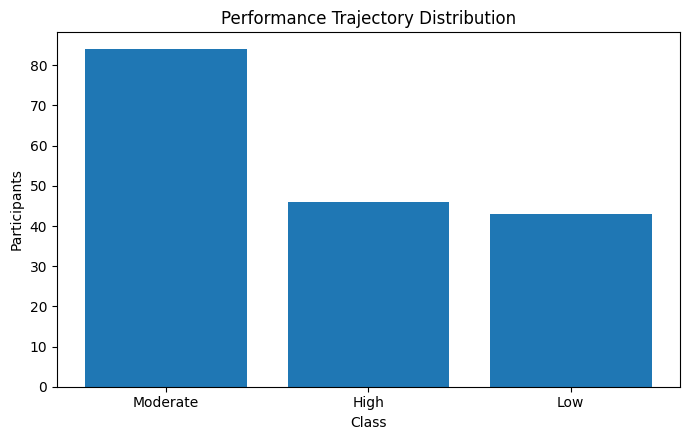

In [4]:
# 3. Check target distribution

target_distribution = (
    primary_df[TARGET_COLUMN]
    .value_counts()
    .rename_axis("Class")
    .reset_index(name="Participants")
)

target_distribution["Percentage"] = (
    target_distribution["Participants"]
    / target_distribution["Participants"].sum()
    * 100
).round(2)

display(target_distribution)

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.bar(
    target_distribution["Class"],
    target_distribution["Participants"]
)

ax.set_title("Performance Trajectory Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Participants")

plt.tight_layout()
plt.show()

## 4. Prepare Target Encoding

In [5]:
# 4. Encode target labels

label_encoder = LabelEncoder()

label_encoder.fit(
    primary_df[TARGET_COLUMN]
)

CLASS_NAMES = list(
    label_encoder.classes_
)

CLASS_TO_CODE = {
    label: int(code)
    for code, label in enumerate(CLASS_NAMES)
}

print("Class mapping:")
print(CLASS_TO_CODE)

Class mapping:
{'High': 0, 'Low': 1, 'Moderate': 2}


## 5. Preprocessing Builder


In [6]:
def build_preprocessor(X):

    numeric_features = (
        X.select_dtypes(
            include=[np.number]
        )
        .columns
        .tolist()
    )

    categorical_features = [
        column
        for column in X.columns
        if column not in numeric_features
    ]

    numeric_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            )
        ]
    )

    categorical_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="infrequent_if_exist",
                    min_frequency=5,
                    sparse_output=False
                )
            )
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_pipeline,
                numeric_features
            ),
            (
                "categorical",
                categorical_pipeline,
                categorical_features
            )
        ],
        remainder="drop"
    )

    return (
        preprocessor,
        numeric_features,
        categorical_features
    )

## 6. Model Definitions and Hyperparameter Grids

In [7]:
# 6. Define models

def get_model_specs(random_state=42):

    logistic = LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        multi_class="auto",
        random_state=random_state
    )

    random_forest = RandomForestClassifier(
        class_weight="balanced",
        random_state=random_state,
        n_jobs=-1
    )

    xgboost = XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=random_state,
        n_jobs=-1
    )

    specs = {
        "Logistic Regression": {
            "estimator": logistic,
            "param_grid": {
                "model__C": [
                    0.1,
                    1.0,
                    10.0
                ]
            }
        },

        "Random Forest": {
            "estimator": random_forest,
            "param_grid": {
                "model__n_estimators": [
                    200,
                    400
                ],
                "model__max_depth": [
                    None,
                    5,
                    10
                ],
                "model__min_samples_leaf": [
                    1,
                    2
                ]
            }
        },

        "XGBoost": {
            "estimator": xgboost,
            "param_grid": {
                "model__n_estimators": [
                    100,
                    200
                ],
                "model__max_depth": [
                    2,
                    4
                ],
                "model__learning_rate": [
                    0.03,
                    0.10
                ],
                "model__subsample": [
                    0.8,
                    1.0
                ]
            }
        }
    }

    return specs

## 7. Nested Cross-Validation Function


In [8]:
# 7. Nested cross-validation function

def run_nested_cv(
    df,
    dataset_name,
    random_state=42
):

    X = df.drop(
        columns=[TARGET_COLUMN]
    ).copy()

    y_text = df[
        TARGET_COLUMN
    ].copy()

    y = label_encoder.transform(
        y_text
    )

    class_counts = pd.Series(
        y
    ).value_counts()

    min_class_count = int(
        class_counts.min()
    )

    if min_class_count < 2:
        raise ValueError(
            "At least one target class has fewer than 2 observations."
        )

    outer_splits = min(
        5,
        min_class_count
    )

    print(
        f"{dataset_name}: using {outer_splits} outer folds"
    )

    outer_cv = StratifiedKFold(
        n_splits=outer_splits,
        shuffle=True,
        random_state=random_state
    )

    model_specs = get_model_specs(
        random_state=random_state
    )

    all_model_results = {}
    summary_rows = []

    for model_name, spec in model_specs.items():

        print()
        print("=" * 60)
        print(dataset_name, "—", model_name)
        print("=" * 60)

        oof_pred = np.full(
            len(X),
            fill_value=-1,
            dtype=int
        )

        oof_proba = np.full(
            (
                len(X),
                len(CLASS_NAMES)
            ),
            fill_value=np.nan,
            dtype=float
        )

        fold_rows = []
        fold_best_params = []

        for fold_number, (
            train_idx,
            test_idx
        ) in enumerate(
            outer_cv.split(X, y),
            start=1
        ):

            X_train = X.iloc[
                train_idx
            ].copy()

            X_test = X.iloc[
                test_idx
            ].copy()

            y_train = y[
                train_idx
            ]

            y_test = y[
                test_idx
            ]

            preprocessor, _, _ = (
                build_preprocessor(
                    X_train
                )
            )

            pipeline = Pipeline(
                steps=[
                    (
                        "preprocess",
                        preprocessor
                    ),
                    (
                        "model",
                        clone(
                            spec[
                                "estimator"
                            ]
                        )
                    )
                ]
            )

            train_class_counts = (
                pd.Series(
                    y_train
                )
                .value_counts()
            )

            inner_splits = min(
                4,
                int(
                    train_class_counts.min()
                )
            )

            inner_splits = max(
                2,
                inner_splits
            )

            inner_cv = StratifiedKFold(
                n_splits=inner_splits,
                shuffle=True,
                random_state=(
                    random_state
                    + fold_number
                )
            )

            search = GridSearchCV(
                estimator=pipeline,
                param_grid=spec[
                    "param_grid"
                ],
                scoring="f1_macro",
                cv=inner_cv,
                n_jobs=-1,
                refit=True
            )

            fit_kwargs = {}

            if model_name == "XGBoost":

                sample_weights = (
                    compute_sample_weight(
                        class_weight="balanced",
                        y=y_train
                    )
                )

                fit_kwargs[
                    "model__sample_weight"
                ] = sample_weights

            search.fit(
                X_train,
                y_train,
                **fit_kwargs
            )

            best_model = (
                search.best_estimator_
            )

            pred = best_model.predict(
                X_test
            )

            proba = (
                best_model
                .predict_proba(
                    X_test
                )
            )

            oof_pred[
                test_idx
            ] = pred

            oof_proba[
                test_idx,
                :
            ] = proba

            try:

                auc = roc_auc_score(
                    y_test,
                    proba,
                    multi_class="ovr",
                    average="macro"
                )

            except ValueError:

                auc = np.nan

            fold_metrics = {
                "Dataset": dataset_name,
                "Model": model_name,
                "Fold": fold_number,
                "Accuracy": accuracy_score(
                    y_test,
                    pred
                ),
                "Balanced Accuracy":
                    balanced_accuracy_score(
                        y_test,
                        pred
                    ),
                "Macro Precision":
                    precision_score(
                        y_test,
                        pred,
                        average="macro",
                        zero_division=0
                    ),
                "Macro Recall":
                    recall_score(
                        y_test,
                        pred,
                        average="macro",
                        zero_division=0
                    ),
                "Macro F1":
                    f1_score(
                        y_test,
                        pred,
                        average="macro",
                        zero_division=0
                    ),
                "Macro ROC-AUC":
                    auc
            }

            fold_rows.append(
                fold_metrics
            )

            fold_best_params.append(
                search.best_params_
            )

            print(
                f"Fold {fold_number}: "
                f"Macro-F1={fold_metrics['Macro F1']:.3f}, "
                f"Balanced Acc={fold_metrics['Balanced Accuracy']:.3f}"
            )

        fold_results = pd.DataFrame(
            fold_rows
        )

        pooled_metrics = {
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": accuracy_score(
                y,
                oof_pred
            ),
            "Balanced Accuracy":
                balanced_accuracy_score(
                    y,
                    oof_pred
                ),
            "Macro Precision":
                precision_score(
                    y,
                    oof_pred,
                    average="macro",
                    zero_division=0
                ),
            "Macro Recall":
                recall_score(
                    y,
                    oof_pred,
                    average="macro",
                    zero_division=0
                ),
            "Macro F1":
                f1_score(
                    y,
                    oof_pred,
                    average="macro",
                    zero_division=0
                )
        }

        try:

            pooled_metrics[
                "Macro ROC-AUC"
            ] = roc_auc_score(
                y,
                oof_proba,
                multi_class="ovr",
                average="macro"
            )

        except ValueError:

            pooled_metrics[
                "Macro ROC-AUC"
            ] = np.nan

        summary_rows.append(
            pooled_metrics
        )

        all_model_results[
            model_name
        ] = {
            "fold_results":
                fold_results,
            "oof_pred":
                oof_pred,
            "oof_proba":
                oof_proba,
            "best_params":
                fold_best_params,
            "true_y":
                y,
            "X":
                X
        }

    summary = pd.DataFrame(
        summary_rows
    )

    summary = summary.sort_values(
        "Macro F1",
        ascending=False
    ).reset_index(
        drop=True
    )

    return (
        summary,
        all_model_results
    )

## 8. Run All Models: Primary Dataset

In [9]:
# 8. Run nested CV on primary modelling dataset

primary_summary, primary_results = (
    run_nested_cv(
        primary_df,
        dataset_name="Primary",
        random_state=42
    )
)

display(primary_summary)

Primary: using 5 outer folds

Primary — Logistic Regression
Fold 1: Macro-F1=0.427, Balanced Acc=0.427
Fold 2: Macro-F1=0.395, Balanced Acc=0.399
Fold 3: Macro-F1=0.365, Balanced Acc=0.377
Fold 4: Macro-F1=0.334, Balanced Acc=0.336
Fold 5: Macro-F1=0.330, Balanced Acc=0.332

Primary — Random Forest
Fold 1: Macro-F1=0.462, Balanced Acc=0.456
Fold 2: Macro-F1=0.297, Balanced Acc=0.307
Fold 3: Macro-F1=0.363, Balanced Acc=0.362
Fold 4: Macro-F1=0.324, Balanced Acc=0.329
Fold 5: Macro-F1=0.368, Balanced Acc=0.373

Primary — XGBoost
Fold 1: Macro-F1=0.443, Balanced Acc=0.444
Fold 2: Macro-F1=0.402, Balanced Acc=0.401
Fold 3: Macro-F1=0.416, Balanced Acc=0.416
Fold 4: Macro-F1=0.312, Balanced Acc=0.310
Fold 5: Macro-F1=0.413, Balanced Acc=0.450


,Dataset,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,Primary,XGBoost,0.421965,0.404938,0.401504,0.404938,0.402823,0.565257
1,Primary,Logistic Regression,0.387283,0.374573,0.375336,0.374573,0.371309,0.588489
2,Primary,Random Forest,0.404624,0.365798,0.368583,0.365798,0.366490,0.583354


## 9. Primary Model Comparison

In [10]:
# 9. Compare primary models

metrics_to_plot = [
    "Macro F1",
    "Balanced Accuracy",
    "Macro ROC-AUC"
]

comparison_plot = (
    primary_summary[
        [
            "Model"
        ] + metrics_to_plot
    ]
    .set_index(
        "Model"
    )
)

display(
    comparison_plot
)

,Macro F1,Balanced Accuracy,Macro ROC-AUC
Model,,,
XGBoost,0.402823,0.404938,0.565257
Logistic Regression,0.371309,0.374573,0.588489
Random Forest,0.366490,0.365798,0.583354


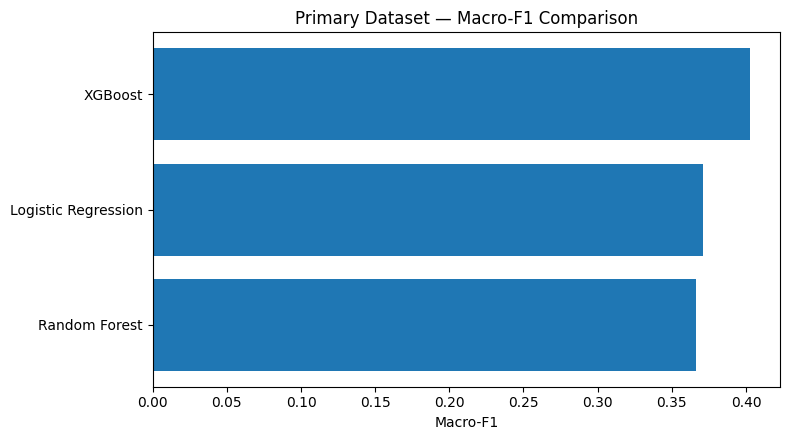

In [11]:
# 9.1 Plot Macro-F1 by model

plot_df = (
    primary_summary
    .sort_values(
        "Macro F1",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(8, 4.5)
)

ax.barh(
    plot_df["Model"],
    plot_df["Macro F1"]
)

ax.set_title(
    "Primary Dataset — Macro-F1 Comparison"
)

ax.set_xlabel(
    "Macro-F1"
)

plt.tight_layout()
plt.show()

## 10. Confusion Matrices: Primary Dataset

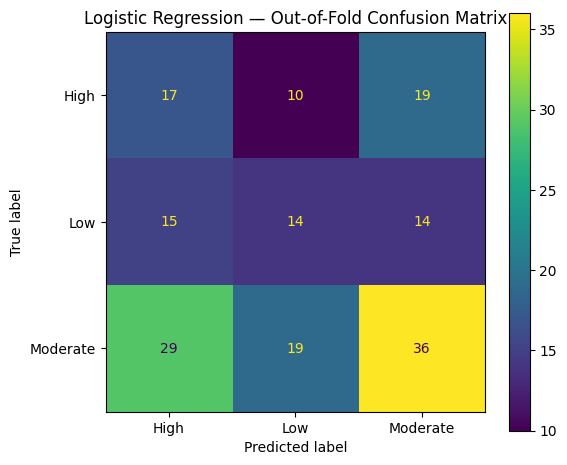

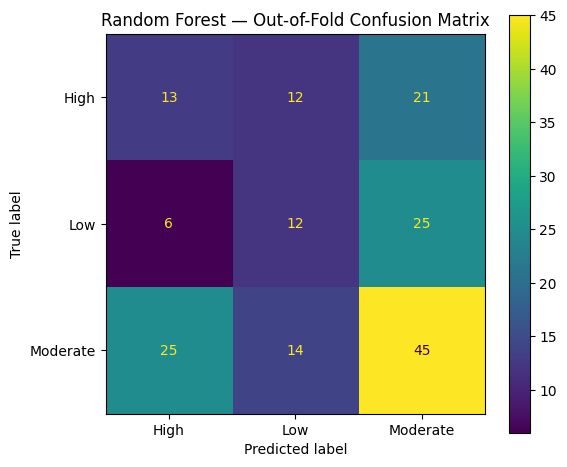

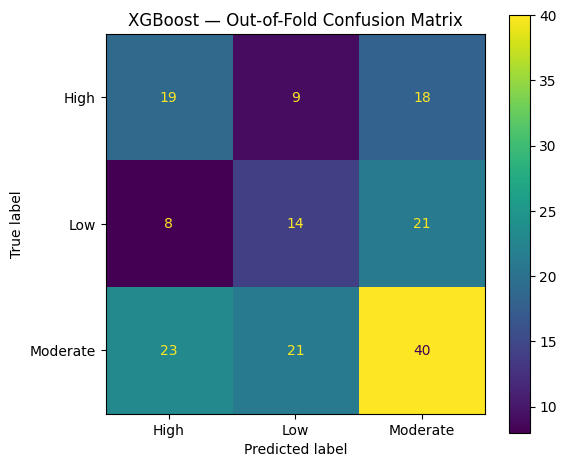

In [12]:
# 10. Confusion matrices from pooled out-of-fold predictions

for model_name, result in primary_results.items():

    y_true = result[
        "true_y"
    ]

    y_pred = result[
        "oof_pred"
    ]

    fig, ax = plt.subplots(
        figsize=(6, 5)
    )

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        display_labels=CLASS_NAMES,
        ax=ax,
        values_format="d"
    )

    ax.set_title(
        f"{model_name} — Out-of-Fold Confusion Matrix"
    )

    plt.tight_layout()
    plt.show()

## 11. Classification Reports - Primary Dataset

In [13]:
# 11. Detailed out-of-fold classification reports

for model_name, result in primary_results.items():

    print()
    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            result["true_y"],
            result["oof_pred"],
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

        High       0.28      0.37      0.32        46
         Low       0.33      0.33      0.33        43
    Moderate       0.52      0.43      0.47        84

    accuracy                           0.39       173
   macro avg       0.38      0.37      0.37       173
weighted avg       0.41      0.39      0.39       173


Random Forest
              precision    recall  f1-score   support

        High       0.30      0.28      0.29        46
         Low       0.32      0.28      0.30        43
    Moderate       0.49      0.54      0.51        84

    accuracy                           0.40       173
   macro avg       0.37      0.37      0.37       173
weighted avg       0.40      0.40      0.40       173


XGBoost
              precision    recall  f1-score   support

        High       0.38      0.41      0.40        46
         Low       0.32      0.33      0.32        43
    Moderate       0.51      0

## 12. Fold-Level Stability

This section checks whether performance is stable across outer folds rather than being driven by one favourable split.

In [14]:
# 12. Combine outer-fold results

primary_fold_results = pd.concat(
    [
        result[
            "fold_results"
        ]
        for result in primary_results.values()
    ],
    ignore_index=True
)

display(
    primary_fold_results
)

,Dataset,Model,Fold,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,Primary,Logistic Regression,1,0.428571,0.427315,0.433712,0.427315,0.427315,0.702991
1,Primary,Logistic Regression,2,0.428571,0.398693,0.443056,0.398693,0.395493,0.629630
2,Primary,Logistic Regression,3,0.371429,0.376906,0.388889,0.376906,0.364522,0.613876
3,Primary,Logistic Regression,4,0.352941,0.336329,0.333333,0.336329,0.333656,0.494182
4,Primary,Logistic Regression,5,0.352941,0.331699,0.345442,0.331699,0.330260,0.552678
5,Primary,Random Forest,1,0.485714,0.456481,0.492063,0.456481,0.462043,0.702636
6,Primary,Random Forest,2,0.371429,0.307190,0.329293,0.307190,0.296671,0.637841
7,Primary,Random Forest,3,0.400000,0.361656,0.370238,0.361656,0.363143,0.588151
8,Primary,Random Forest,4,0.382353,0.329248,0.322222,0.329248,0.324311,0.451001
9,Primary,Random Forest,5,0.382353,0.373366,0.401166,0.373366,0.368078,0.542480


In [15]:
# 12.1 Mean and standard deviation across outer folds

primary_cv_summary = (
    primary_fold_results
    .groupby("Model")
    .agg(
        Macro_F1_Mean=(
            "Macro F1",
            "mean"
        ),
        Macro_F1_SD=(
            "Macro F1",
            "std"
        ),
        Balanced_Accuracy_Mean=(
            "Balanced Accuracy",
            "mean"
        ),
        Balanced_Accuracy_SD=(
            "Balanced Accuracy",
            "std"
        ),
        ROC_AUC_Mean=(
            "Macro ROC-AUC",
            "mean"
        ),
        ROC_AUC_SD=(
            "Macro ROC-AUC",
            "std"
        )
    )
    .reset_index()
    .sort_values(
        "Macro_F1_Mean",
        ascending=False
    )
)

display(
    primary_cv_summary
)

,Model,Macro_F1_Mean,Macro_F1_SD,Balanced_Accuracy_Mean,Balanced_Accuracy_SD,ROC_AUC_Mean,ROC_AUC_SD
2,XGBoost,0.397219,0.050018,0.404194,0.056573,0.573147,0.074669
0,Logistic Regression,0.370249,0.041427,0.374188,0.040832,0.598671,0.079224
1,Random Forest,0.362849,0.062713,0.365588,0.057159,0.584422,0.095397


## 13. Hyperparameters Selected Across Outer Folds

In [16]:
# 13. Review selected hyperparameters

for model_name, result in primary_results.items():

    print()
    print(model_name)

    for fold_number, params in enumerate(
        result[
            "best_params"
        ],
        start=1
    ):
        print(
            f"Fold {fold_number}:",
            params
        )


Logistic Regression
Fold 1: {'model__C': 0.1}
Fold 2: {'model__C': 0.1}
Fold 3: {'model__C': 1.0}
Fold 4: {'model__C': 10.0}
Fold 5: {'model__C': 0.1}

Random Forest
Fold 1: {'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Fold 2: {'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Fold 3: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Fold 4: {'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__n_estimators': 400}
Fold 5: {'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}

XGBoost
Fold 1: {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 200, 'model__subsample': 1.0}
Fold 2: {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 200, 'model__subsample': 0.8}
Fold 3: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 0.8}
Fold 4: {'model__learning_ra

## 14. Run All Models: Sensitivity Dataset


In [17]:
# 14. Run sensitivity models

RUN_SENSITIVITY = True

if (
    RUN_SENSITIVITY
    and sensitivity_df is not None
):

    sensitivity_summary, sensitivity_results = (
        run_nested_cv(
            sensitivity_df,
            dataset_name="Sensitivity",
            random_state=42
        )
    )

    display(
        sensitivity_summary
    )

else:

    sensitivity_summary = pd.DataFrame()
    sensitivity_results = {}

    print(
        "Sensitivity analysis skipped."
    )

Sensitivity: using 5 outer folds

Sensitivity — Logistic Regression
Fold 1: Macro-F1=0.537, Balanced Acc=0.543
Fold 2: Macro-F1=0.518, Balanced Acc=0.510
Fold 3: Macro-F1=0.547, Balanced Acc=0.582
Fold 4: Macro-F1=0.372, Balanced Acc=0.378
Fold 5: Macro-F1=0.318, Balanced Acc=0.319

Sensitivity — Random Forest
Fold 1: Macro-F1=0.586, Balanced Acc=0.572
Fold 2: Macro-F1=0.331, Balanced Acc=0.346
Fold 3: Macro-F1=0.503, Balanced Acc=0.545
Fold 4: Macro-F1=0.445, Balanced Acc=0.432
Fold 5: Macro-F1=0.454, Balanced Acc=0.454

Sensitivity — XGBoost
Fold 1: Macro-F1=0.516, Balanced Acc=0.519
Fold 2: Macro-F1=0.348, Balanced Acc=0.342
Fold 3: Macro-F1=0.477, Balanced Acc=0.490
Fold 4: Macro-F1=0.350, Balanced Acc=0.354
Fold 5: Macro-F1=0.362, Balanced Acc=0.369


,Dataset,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,Sensitivity,Random Forest,0.497110,0.470910,0.480973,0.470910,0.473416,0.670823
1,Sensitivity,Logistic Regression,0.468208,0.467460,0.462698,0.467460,0.462830,0.653308
2,Sensitivity,XGBoost,0.421965,0.417301,0.411996,0.417301,0.413752,0.623590


## 15. Primary vs Sensitivity Comparison

In [18]:
# 15. Compare primary and sensitivity model performance

if len(sensitivity_summary):

    scenario_comparison = pd.concat(
        [
            primary_summary,
            sensitivity_summary
        ],
        ignore_index=True
    )

    scenario_comparison = (
        scenario_comparison
        .sort_values(
            [
                "Model",
                "Dataset"
            ]
        )
    )

    display(
        scenario_comparison
    )

else:

    scenario_comparison = (
        primary_summary.copy()
    )

    display(
        scenario_comparison
    )

,Dataset,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
1,Primary,Logistic Regression,0.387283,0.374573,0.375336,0.374573,0.371309,0.588489
4,Sensitivity,Logistic Regression,0.468208,0.467460,0.462698,0.467460,0.462830,0.653308
2,Primary,Random Forest,0.404624,0.365798,0.368583,0.365798,0.366490,0.583354
3,Sensitivity,Random Forest,0.497110,0.470910,0.480973,0.470910,0.473416,0.670823
0,Primary,XGBoost,0.421965,0.404938,0.401504,0.404938,0.402823,0.565257
5,Sensitivity,XGBoost,0.421965,0.417301,0.411996,0.417301,0.413752,0.623590


In [19]:
# 15.1 Macro-F1 change after adding baseline financial variables

if len(sensitivity_summary):

    primary_f1 = (
        primary_summary[
            [
                "Model",
                "Macro F1"
            ]
        ]
        .rename(
            columns={
                "Macro F1":
                    "Primary Macro F1"
            }
        )
    )

    sensitivity_f1 = (
        sensitivity_summary[
            [
                "Model",
                "Macro F1"
            ]
        ]
        .rename(
            columns={
                "Macro F1":
                    "Sensitivity Macro F1"
            }
        )
    )

    sensitivity_effect = (
        primary_f1
        .merge(
            sensitivity_f1,
            on="Model",
            how="inner"
        )
    )

    sensitivity_effect[
        "Macro F1 Difference"
    ] = (
        sensitivity_effect[
            "Sensitivity Macro F1"
        ]
        - sensitivity_effect[
            "Primary Macro F1"
        ]
    )

    display(
        sensitivity_effect
    )

,Model,Primary Macro F1,Sensitivity Macro F1,Macro F1 Difference
0,XGBoost,0.402823,0.413752,0.010929
1,Logistic Regression,0.371309,0.462830,0.091521
2,Random Forest,0.366490,0.473416,0.106926


## 16. Select Best Primary Model

The main comparison criterion is Macro-F1.

Balanced Accuracy and ROC-AUC should also be considered, especially if the class distribution is imbalanced.

In [20]:
# 16. Identify best primary model by Macro-F1

best_model_name = (
    primary_summary
    .sort_values(
        "Macro F1",
        ascending=False
    )
    .iloc[0][
        "Model"
    ]
)

print(
    "Best primary model by Macro-F1:",
    best_model_name
)

display(
    primary_summary[
        primary_summary[
            "Model"
        ].eq(
            best_model_name
        )
    ]
)

Best primary model by Macro-F1: XGBoost


,Dataset,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,Primary,XGBoost,0.421965,0.404938,0.401504,0.404938,0.402823,0.565257


In [22]:
# 16.1 Final model selection review

selection_review = (
    primary_summary
    .copy()
)

# Add fold-level stability
fold_stability = (
    primary_fold_results
    .groupby("Model")
    .agg(
        CV_Macro_F1_Mean=(
            "Macro F1",
            "mean"
        ),
        CV_Macro_F1_SD=(
            "Macro F1",
            "std"
        )
    )
    .reset_index()
)

selection_review = (
    selection_review
    .merge(
        fold_stability,
        on="Model",
        how="left"
    )
)

# Define oof_predictions here
oof_frames = []

for model_name_oof, result_oof in primary_results.items():

    frame = pd.DataFrame({
        "Row Index": np.arange(
            len(primary_df)
        ),
        "Actual Label": label_encoder.inverse_transform(
            result_oof[
                "true_y"
            ]
        ),
        "Predicted Label": label_encoder.inverse_transform(
            result_oof[
                "oof_pred"
            ]
        ),
        "Model": model_name_oof
    })

    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):

        frame[
            f"Probability_{class_name}"
        ] = result_oof[
            "oof_proba"
        ][
            :,
            class_index
        ]

    oof_frames.append(
        frame
    )

oof_predictions = pd.concat(
    oof_frames,
    ignore_index=True
)


# Add Low-class performance
low_metrics = []

for model_name in (
    oof_predictions[
        "Model"
    ]
    .dropna()
    .unique()
):

    model_oof = (
        oof_predictions[
            oof_predictions[
                "Model"
            ]
            == model_name
        ]
        .copy()
    )

    actual_low = (
        model_oof[
            "Actual Label"
        ]
        == "Low"
    )

    predicted_low = (
        model_oof[
            "Predicted Label"
        ]
        == "Low"
    )

    tp = (
        actual_low
        & predicted_low
    ).sum()

    fn = (
        actual_low
        & ~predicted_low
    ).sum()

    low_recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    low_metrics.append({
        "Model": model_name,
        "Low Recall": low_recall
    })

low_metrics = pd.DataFrame(
    low_metrics
)

selection_review = (
    selection_review
    .merge(
        low_metrics,
        on="Model",
        how="left"
    )
)

selection_review = (
    selection_review[
        [
            "Model",
            "Macro F1",
            "Balanced Accuracy",
            "Low Recall",
            "Macro ROC-AUC",
            "CV_Macro_F1_Mean",
            "CV_Macro_F1_SD"
        ]
    ]
    .sort_values(
        "Macro F1",
        ascending=False
    )
)

display(
    selection_review
)

print(
    "Primary selection rule:"
)
print(
    "1. Highest Macro-F1"
)
print(
    "2. Check Low-class recall is not inferior"
)
print(
    "3. Review balanced accuracy and CV stability"
)
print(
    "4. ROC-AUC is supporting, not sole selection metric"
)

selected_model_name = (
    selection_review
    .iloc[0][
        "Model"
    ]
)

print()
print(
    "Selected final primary model:",
    selected_model_name
)


,Model,Macro F1,Balanced Accuracy,Low Recall,Macro ROC-AUC,CV_Macro_F1_Mean,CV_Macro_F1_SD
0,XGBoost,0.402823,0.404938,0.325581,0.565257,0.397219,0.050018
1,Logistic Regression,0.371309,0.374573,0.325581,0.588489,0.370249,0.041427
2,Random Forest,0.366490,0.365798,0.279070,0.583354,0.362849,0.062713


Primary selection rule:
1. Highest Macro-F1
2. Check Low-class recall is not inferior
3. Review balanced accuracy and CV stability
4. ROC-AUC is supporting, not sole selection metric

Selected final primary model: XGBoost


## 17. Fit a Final Tuned Version of Each Model on the Full Primary Dataset


In [23]:
# 17. Final tuning on all primary data

X_full = primary_df.drop(
    columns=[TARGET_COLUMN]
).copy()

y_full = label_encoder.transform(
    primary_df[TARGET_COLUMN]
)

preprocessor, numeric_features, categorical_features = (
    build_preprocessor(
        X_full
    )
)

final_model_specs = get_model_specs(
    random_state=42
)

min_class_count = int(
    pd.Series(
        y_full
    ).value_counts().min()
)

final_inner_splits = min(
    5,
    min_class_count
)

final_inner_splits = max(
    2,
    final_inner_splits
)

final_cv = StratifiedKFold(
    n_splits=final_inner_splits,
    shuffle=True,
    random_state=42
)

final_tuned_models = {}
final_best_params = {}

for model_name, spec in final_model_specs.items():

    print()
    print(
        "Final tuning:",
        model_name
    )

    pipeline = Pipeline(
        steps=[
            (
                "preprocess",
                clone(
                    preprocessor
                )
            ),
            (
                "model",
                clone(
                    spec[
                        "estimator"
                    ]
                )
            )
        ]
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=spec[
            "param_grid"
        ],
        scoring="f1_macro",
        cv=final_cv,
        n_jobs=-1,
        refit=True
    )

    fit_kwargs = {}

    if model_name == "XGBoost":

        sample_weights = (
            compute_sample_weight(
                class_weight="balanced",
                y=y_full
            )
        )

        fit_kwargs[
            "model__sample_weight"
        ] = sample_weights

    search.fit(
        X_full,
        y_full,
        **fit_kwargs
    )

    final_tuned_models[
        model_name
    ] = search.best_estimator_

    final_best_params[
        model_name
    ] = search.best_params_

    print(
        "Best parameters:",
        search.best_params_
    )


Final tuning: Logistic Regression
Best parameters: {'model__C': 0.1}

Final tuning: Random Forest
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}

Final tuning: XGBoost
Best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 1.0}


## 18. Model-Based Feature Importance

In [24]:
# 18. Extract transformed feature names

fitted_preprocessor = (
    final_tuned_models[
        best_model_name
    ]
    .named_steps[
        "preprocess"
    ]
)

feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

print(
    "Transformed features:",
    len(feature_names)
)

Transformed features: 35


In [25]:
# 18.1 Logistic Regression coefficient magnitude

logistic_model = (
    final_tuned_models[
        "Logistic Regression"
    ]
    .named_steps[
        "model"
    ]
)

logistic_importance = (
    np.abs(
        logistic_model.coef_
    )
    .mean(axis=0)
)

logistic_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": logistic_importance
}).sort_values(
    "Importance",
    ascending=False
)

display(
    logistic_feature_importance.head(20)
)

,Feature,Importance
5,numeric__digital_platform_count,0.211496
28,categorical__Industry/Business Sector_Beauty &...,0.195674
13,numeric__overall_competency_change_z,0.154877
0,numeric__Age,0.152224
9,numeric__attendance_rate,0.150305
11,numeric__behavior_avg_deduct_per_session,0.148851
15,categorical__State_Kuala Lumpur,0.144584
6,numeric__IG_followers_pre,0.142386
25,categorical__Working Status_Housewife,0.141753
23,categorical__Education Level_SPM,0.124186


In [26]:
# 18.2 Random Forest feature importance

rf_model = (
    final_tuned_models[
        "Random Forest"
    ]
    .named_steps[
        "model"
    ]
)

rf_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(
    rf_feature_importance.head(20)
)

,Feature,Importance
3,numeric__Estimated Remaining Balance,0.102344
12,numeric__behavior_final_z_in_cohort,0.086384
2,numeric__Household Income,0.078399
7,numeric__FB_followers_pre,0.076317
13,numeric__overall_competency_change_z,0.073228
6,numeric__IG_followers_pre,0.069377
8,numeric__TT_followers_pre,0.067362
10,numeric__behavior_avg_gain_per_session,0.067085
1,numeric__Years in Business,0.062666
5,numeric__digital_platform_count,0.050914


In [27]:
# 18.3 XGBoost feature importance

xgb_model = (
    final_tuned_models[
        "XGBoost"
    ]
    .named_steps[
        "model"
    ]
)

xgb_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(
    xgb_feature_importance.head(20)
)

,Feature,Importance
0,numeric__Age,0.078248
5,numeric__digital_platform_count,0.070437
11,numeric__behavior_avg_deduct_per_session,0.068839
16,categorical__State_Selangor,0.060274
28,categorical__Industry/Business Sector_Beauty &...,0.058487
13,numeric__overall_competency_change_z,0.057704
10,numeric__behavior_avg_gain_per_session,0.056174
17,categorical__State_infrequent_sklearn,0.055988
3,numeric__Estimated Remaining Balance,0.055105
9,numeric__attendance_rate,0.050680


## 19. Save Model Results


- pooled model comparison;
- fold-level cross-validation results;
- primary vs sensitivity comparison;
- selected hyperparameters;
- out-of-fold predictions;
- feature-importance tables.


In [28]:
# 19. Save summary results

PRIMARY_SUMMARY_PATH = (
    RESULTS_DIR
    / "primary_model_comparison.csv"
)

PRIMARY_CV_PATH = (
    RESULTS_DIR
    / "primary_nested_cv_fold_results.csv"
)

SCENARIO_PATH = (
    RESULTS_DIR
    / "primary_vs_sensitivity_comparison.csv"
)

PARAMS_PATH = (
    RESULTS_DIR
    / "final_best_parameters.json"
)

LOGISTIC_IMPORTANCE_PATH = (
    RESULTS_DIR
    / "logistic_feature_importance.csv"
)

RF_IMPORTANCE_PATH = (
    RESULTS_DIR
    / "random_forest_feature_importance.csv"
)

XGB_IMPORTANCE_PATH = (
    RESULTS_DIR
    / "xgboost_feature_importance.csv"
)

primary_summary.to_csv(
    PRIMARY_SUMMARY_PATH,
    index=False
)

primary_fold_results.to_csv(
    PRIMARY_CV_PATH,
    index=False
)

scenario_comparison.to_csv(
    SCENARIO_PATH,
    index=False
)

with open(
    PARAMS_PATH,
    "w"
) as file:

    json.dump(
        final_best_params,
        file,
        indent=2
    )

logistic_feature_importance.to_csv(
    LOGISTIC_IMPORTANCE_PATH,
    index=False
)

rf_feature_importance.to_csv(
    RF_IMPORTANCE_PATH,
    index=False
)

xgb_feature_importance.to_csv(
    XGB_IMPORTANCE_PATH,
    index=False
)

print("Saved model results to:")
print(RESULTS_DIR)

Saved model results to:
/content/drive/MyDrive/24088950_MAI_Research/outputs/model_results


In [29]:
# 19.1 Save primary out-of-fold predictions

oof_frames = []

for model_name, result in primary_results.items():

    frame = pd.DataFrame({
        "Row Index": np.arange(
            len(primary_df)
        ),
        "Actual": label_encoder.inverse_transform(
            result[
                "true_y"
            ]
        ),
        "Predicted": label_encoder.inverse_transform(
            result[
                "oof_pred"
            ]
        ),
        "Model": model_name
    })

    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):

        frame[
            f"Probability_{class_name}"
        ] = result[
            "oof_proba"
        ][
            :,
            class_index
        ]

    oof_frames.append(
        frame
    )

primary_oof_predictions = pd.concat(
    oof_frames,
    ignore_index=True
)

OOF_PATH = (
    RESULTS_DIR
    / "primary_out_of_fold_predictions.csv"
)

primary_oof_predictions.to_csv(
    OOF_PATH,
    index=False
)

display(
    primary_oof_predictions.head()
)

print(
    "Saved:",
    OOF_PATH
)

,Row Index,Actual,Predicted,Model,Probability_High,Probability_Low,Probability_Moderate
0,0,High,High,Logistic Regression,0.420337,0.305239,0.274424
1,1,High,High,Logistic Regression,0.660169,0.079587,0.260244
2,2,Moderate,High,Logistic Regression,0.435721,0.212050,0.352229
3,3,Moderate,High,Logistic Regression,0.639428,0.030614,0.329958
4,4,High,High,Logistic Regression,0.564843,0.064976,0.370181


Saved: /content/drive/MyDrive/24088950_MAI_Research/outputs/model_results/primary_out_of_fold_predictions.csv


In [30]:
# 20. Final summary

print("ALL MODELS COMPLETE")
print()

display(
    primary_summary
)

print()

print(
    "Best primary model by Macro-F1:",
    best_model_name
)

print()

print(
    "Results saved to:",
    RESULTS_DIR
)

ALL MODELS COMPLETE



,Dataset,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,Primary,XGBoost,0.421965,0.404938,0.401504,0.404938,0.402823,0.565257
1,Primary,Logistic Regression,0.387283,0.374573,0.375336,0.374573,0.371309,0.588489
2,Primary,Random Forest,0.404624,0.365798,0.368583,0.365798,0.366490,0.583354



Best primary model by Macro-F1: XGBoost

Results saved to: /content/drive/MyDrive/24088950_MAI_Research/outputs/model_results
